# ME256 Homework 2: reflection and refraction

**Assignment statement:** [ME256 Homework 2 (2011)](https://mecheng.iisc.ac.in/suresh/me256/hw2011/homework2.html). This notebook builds runnable geometric-optics models using Python, NumPy, SciPy, and Matplotlib.

The models cover a circular-mirror sweep, a straight mirror, circular and cylindrical reflecting surfaces, and travel-time minimization through a planar interface. The points on each reflecting surface are parameterized by angle (and, for the cylinder, height); each path objective is the sum of endpoint-to-surface distances. Refraction minimizes distance divided by propagation speed in each medium.

## Stationarity and classification

A stationary surface point satisfies equality of the tangential components of the incoming and outgoing path gradients. For path length, this is the reflection condition. For travel time, the corresponding gradient condition gives Snell's law. A stationary point can be a minimum, maximum, or saddle depending on the second variation; a solver's status alone does not provide that classification. The circular-mirror cell explicitly searches all sampled local extrema on the periodic domain; the cylinder cells search bounded angle-height domains from a grid of starts.

## Reproduction

Run all cells with Python 3 and NumPy, SciPy, and Matplotlib. The saved figures and printed values are generated by the notebook itself.

## 1. Circular mirror: sweep the reflection point

The reflection point is $z(\\theta)=(\\cos\\theta,\\sin\\theta)$. The plot compares total path length with signed ray-to-tangent angles as the point moves around the unit circle. Selected angle gaps avoid the near-vertical slope cases in the sampled curve.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar


In [2]:
def circular_path_length(angle, source, destination, radius=1.0):
    reflection_point = radius * np.array([np.cos(angle), np.sin(angle)])
    return np.linalg.norm(source - reflection_point) + np.linalg.norm(
        destination - reflection_point
    )


def periodic_extreme(source, destination, maximize=False, sample_count=720):
    step = 2.0 * np.pi / sample_count
    grid = np.linspace(-np.pi, np.pi, sample_count, endpoint=False)
    values = np.array(
        [circular_path_length(angle, source, destination) for angle in grid]
    )
    signed_objective = -1.0 if maximize else 1.0
    candidates = []
    for index, value in enumerate(values):
        previous_value = values[(index - 1) % sample_count]
        next_value = values[(index + 1) % sample_count]
        is_local_extreme = (
            value >= previous_value and value >= next_value
            if maximize
            else value <= previous_value and value <= next_value
        )
        if not is_local_extreme:
            continue
        center = grid[index]
        result = minimize_scalar(
            lambda angle: signed_objective
            * circular_path_length(angle, source, destination),
            bounds=(center - step, center + step),
            method="bounded",
            options={"xatol": 1e-13},
        )
        candidates.append((result.x, signed_objective * result.fun))
    if not candidates:
        raise RuntimeError("The periodic search found no candidate extrema.")
    return (max if maximize else min)(candidates, key=lambda candidate: candidate[1])


def reflection_point_on_circle(angle, radius=1.0):
    return radius * np.array([np.cos(angle), np.sin(angle)])


def tangent_angle_from_ray(angle, ray_vector):
    tangent = np.array([-np.sin(angle), np.cos(angle)])
    return np.arctan2(
        tangent[0] * ray_vector[1] - tangent[1] * ray_vector[0],
        np.dot(tangent, ray_vector),
    )


sampled 199 points on a unit-radius circular mirror; path length range=1.515155 to 2.975306


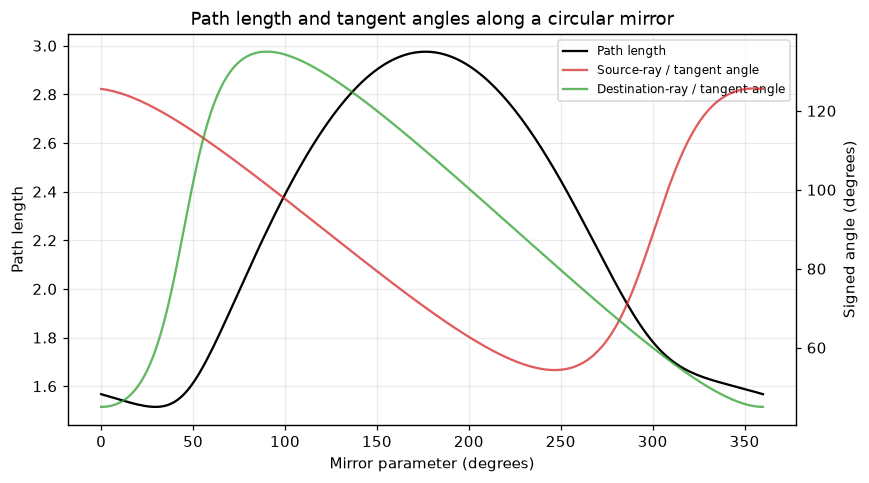

In [3]:
source_point = np.array([0.3, -0.5])
destination_point = np.array([0.5, 0.5])
angles = np.r_[
    np.arange(0, 50) * np.pi / 100,
    np.arange(51, 150) * np.pi / 100,
    np.arange(151, 201) * np.pi / 100,
]
reflection_points = np.array(
    [reflection_point_on_circle(angle) for angle in angles]
)
path_lengths = np.array(
    [
        circular_path_length(angle, source_point, destination_point)
        for angle in angles
    ]
)
source_rays = source_point - reflection_points
destination_rays = destination_point - reflection_points
incidence_angles = np.array(
    [
        tangent_angle_from_ray(angle, ray)
        for angle, ray in zip(angles, source_rays)
    ]
)
reflection_angles = np.array(
    [
        tangent_angle_from_ray(angle, ray)
        for angle, ray in zip(angles, destination_rays)
    ]
)
print(
    f"sampled {len(angles)} points on a unit-radius circular mirror; "
    f"path length range={path_lengths.min():.6f} to {path_lengths.max():.6f}"
)

figure, distance_axes = plt.subplots(figsize=(8, 4.5))
distance_axes.plot(np.degrees(angles), path_lengths, color="black", label="Path length")
distance_axes.set(xlabel="Mirror parameter (degrees)", ylabel="Path length")
angle_axes = distance_axes.twinx()
angle_axes.plot(
    np.degrees(angles), np.degrees(incidence_angles), color="tab:red", alpha=0.75,
    label="Source-ray / tangent angle",
)
angle_axes.plot(
    np.degrees(angles), np.degrees(reflection_angles), color="tab:green", alpha=0.75,
    label="Destination-ray / tangent angle",
)
angle_axes.set_ylabel("Signed angle (degrees)")
distance_axes.set_title("Path length and tangent angles along a circular mirror")
distance_axes.grid(True, alpha=0.25)
lines = distance_axes.lines + angle_axes.lines
distance_axes.legend(lines, [line.get_label() for line in lines], fontsize=8)
figure.tight_layout()
plt.show()


## 2. Straight mirror: constrained path minimization

Minimize $\\|x-z\\|+\\|y-z\\|$ subject to the mirror equation $z_y-2z_x-3=0$. The optimizer returns a point on the mirror, and the plot shows the two line segments.

converged=True; reflection point=[1.24000002 5.48000004]; path length=5.81377674; line residual=4.44e-16


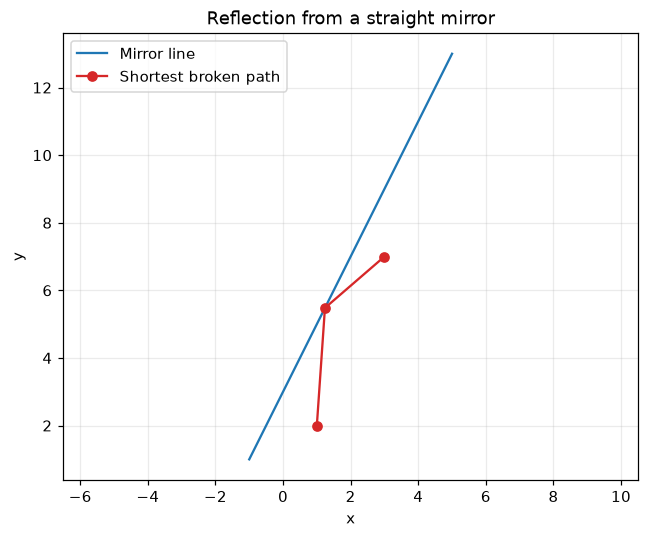

In [4]:
source_point = np.array([1.0, 2.0])
destination_point = np.array([3.0, 7.0])
mirror_slope, mirror_intercept = 2.0, 3.0

def plane_mirror_objective(reflection_point):
    return np.linalg.norm(source_point - reflection_point) + np.linalg.norm(
        destination_point - reflection_point
    )

plane_result = minimize(
    plane_mirror_objective,
    np.array([0.0, mirror_intercept]),
    method="SLSQP",
    constraints={
        "type": "eq",
        "fun": lambda point: point[1] - mirror_slope * point[0] - mirror_intercept,
        "jac": lambda point: np.array([-mirror_slope, 1.0]),
    },
    options={"maxiter": 500, "ftol": 1e-12},
)
if not plane_result.success:
    raise RuntimeError(f"Plane-mirror optimization failed: {plane_result.message}")
reflection_point = plane_result.x
print(
    f"converged={plane_result.success}; reflection point={reflection_point}; "
    f"path length={plane_result.fun:.8f}; line residual="
    f"{reflection_point[1] - mirror_slope * reflection_point[0] - mirror_intercept:.2e}"
)

mirror_x = np.linspace(-1.0, 5.0, 200)
figure, axes = plt.subplots(figsize=(6, 5))
axes.plot(mirror_x, mirror_slope * mirror_x + mirror_intercept, label="Mirror line")
axes.plot(
    [source_point[0], reflection_point[0], destination_point[0]],
    [source_point[1], reflection_point[1], destination_point[1]],
    "o-",
    color="tab:red",
    label="Shortest broken path",
)
axes.set(xlabel="x", ylabel="y", title="Reflection from a straight mirror")
axes.set_aspect("equal", adjustable="datalim")
axes.grid(True, alpha=0.25)
axes.legend()
figure.tight_layout()
plt.show()


## 3. Concave circular mirror: minimum and maximum path

Both endpoints lie inside a unit-radius circle. A periodic grid identifies every sampled local extremum, then a bounded scalar search refines each candidate. The smallest and largest path values on the circle are plotted.

minimum: angle=2.040892 rad; path=1.22747962; maximum: angle=-1.612349 rad; path=3.35385109


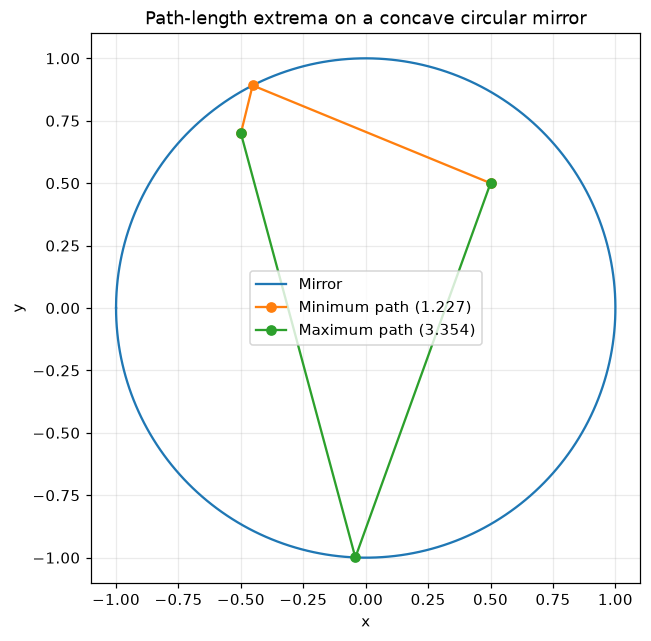

In [5]:
source_point = np.array([-0.5, 0.7])
destination_point = np.array([0.5, 0.5])
radius = 1.0
if np.linalg.norm(source_point) > radius or np.linalg.norm(destination_point) > radius:
    raise ValueError("Both endpoints must lie inside the circular mirror.")

minimum_angle, minimum_length = periodic_extreme(
    source_point, destination_point, maximize=False
)
maximum_angle, maximum_length = periodic_extreme(
    source_point, destination_point, maximize=True
)
minimum_point = reflection_point_on_circle(minimum_angle, radius)
maximum_point = reflection_point_on_circle(maximum_angle, radius)
print(
    f"minimum: angle={minimum_angle:.6f} rad; path={minimum_length:.8f}; "
    f"maximum: angle={maximum_angle:.6f} rad; path={maximum_length:.8f}"
)

circle_angles = np.linspace(-np.pi, np.pi, 500)
figure, axes = plt.subplots(figsize=(6, 6))
axes.plot(radius * np.cos(circle_angles), radius * np.sin(circle_angles), label="Mirror")
axes.plot(
    [source_point[0], minimum_point[0], destination_point[0]],
    [source_point[1], minimum_point[1], destination_point[1]],
    "o-",
    label=f"Minimum path ({minimum_length:.3f})",
)
axes.plot(
    [source_point[0], maximum_point[0], destination_point[0]],
    [source_point[1], maximum_point[1], destination_point[1]],
    "o-",
    label=f"Maximum path ({maximum_length:.3f})",
)
axes.set(xlabel="x", ylabel="y", title="Path-length extrema on a concave circular mirror")
axes.set_aspect("equal")
axes.grid(True, alpha=0.25)
axes.legend()
figure.tight_layout()
plt.show()


## 4–5. Cylindrical mirror: interior and exterior endpoints

Parameterize the finite cylinder by $(\\cos\\theta,\\sin\\theta,z)$, with the reflection height bounded by the endpoint heights. Deterministic angle-height starting grids reduce sensitivity to a single local starting point. The reported values are the best converged candidates among those starts; they are not a proof of global optimality.

The endpoint-to-surface distances use each endpoint's own three coordinates. Both the minimum- and maximum-path searches use the same physical path-length model.

In [6]:
def cylindrical_path(parameters, source, destination, radius=1.0):
    angle, height = parameters
    reflection_point = np.array(
        [radius * np.cos(angle), radius * np.sin(angle), height]
    )
    return np.linalg.norm(source - reflection_point) + np.linalg.norm(
        destination - reflection_point
    )


def cylindrical_extreme(source, destination, angle_bounds, maximize=False):
    height_bounds = (min(source[2], destination[2]), max(source[2], destination[2]))
    starts = [
        (angle, height)
        for angle in np.linspace(angle_bounds[0], angle_bounds[1], 9)
        for height in np.linspace(height_bounds[0], height_bounds[1], 3)
    ]
    sign = -1.0 if maximize else 1.0
    candidates = []
    for start in starts:
        result = minimize(
            lambda parameters: sign * cylindrical_path(parameters, source, destination),
            np.asarray(start),
            method="L-BFGS-B",
            bounds=[angle_bounds, height_bounds],
            options={"maxiter": 1000, "ftol": 1e-14, "gtol": 1e-9},
        )
        if result.success:
            candidates.append((result, sign * result.fun))
    if not candidates:
        raise RuntimeError("No cylindrical-mirror search start converged.")
    return (max if maximize else min)(candidates, key=lambda item: item[1])


def plot_cylinder_paths(source, destination, extrema, title):
    angle_grid = np.linspace(-np.pi, np.pi, 120)
    height_grid = np.linspace(min(source[2], destination[2]), max(source[2], destination[2]), 20)
    angle_mesh, height_mesh = np.meshgrid(angle_grid, height_grid)
    surface_x = np.cos(angle_mesh)
    surface_y = np.sin(angle_mesh)
    figure = plt.figure(figsize=(7, 5))
    axes = figure.add_subplot(111, projection="3d")
    axes.plot_surface(surface_x, surface_y, height_mesh, alpha=0.25, color="steelblue")
    axes.scatter(*source, color="black", s=28, label="Source")
    axes.scatter(*destination, color="gray", s=28, label="Destination")
    for label, (result, path_length), color in zip(
        ("Minimum", "Maximum"), extrema, ("tab:red", "tab:orange")
    ):
        angle, height = result.x
        reflection = np.array([np.cos(angle), np.sin(angle), height])
        axes.plot(
            [source[0], reflection[0], destination[0]],
            [source[1], reflection[1], destination[1]],
            [source[2], reflection[2], destination[2]],
            color=color,
            marker="o",
            label=f"{label} path ({path_length:.3f})",
        )
    axes.set(xlabel="x", ylabel="y", zlabel="z", title=title)
    axes.legend(fontsize=8)
    figure.tight_layout()
    plt.show()


minimum: converged=True; point=[5.40074256 0.26496679]; path=1.74721096; maximum: converged=True; point=[1.26634836 0.3       ]; path=2.65473291


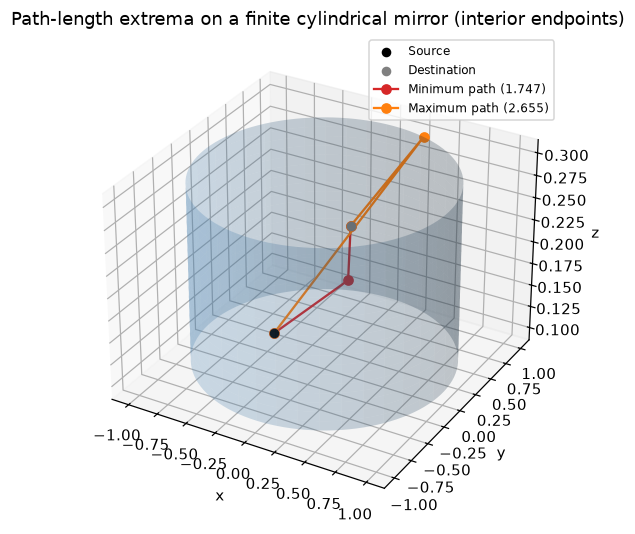

In [7]:
source_point = np.array([-0.5, 0.1, 0.1])
destination_point = np.array([0.5, -0.5, 0.3])
minimum = cylindrical_extreme(
    source_point, destination_point, (0.0, 2.0 * np.pi), maximize=False
)
maximum = cylindrical_extreme(
    source_point, destination_point, (-np.pi, np.pi), maximize=True
)
print(
    f"minimum: converged={minimum[0].success}; point={minimum[0].x}; "
    f"path={minimum[1]:.8f}; maximum: converged={maximum[0].success}; "
    f"point={maximum[0].x}; path={maximum[1]:.8f}"
)
plot_cylinder_paths(
    source_point, destination_point, (minimum, maximum),
    "Path-length extrema on a finite cylindrical mirror (interior endpoints)",
)


minimum: converged=True; point=[-0.35203934  0.22772848]; path=13.14329660; maximum: converged=True; point=[2.87028444 0.1       ]; path=14.35255697


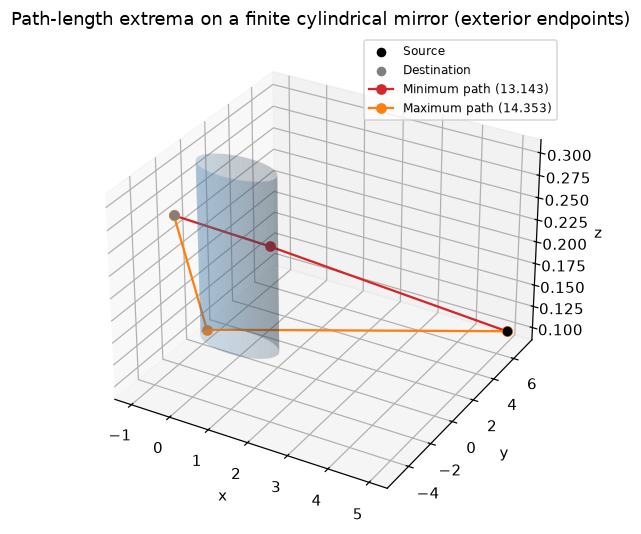

In [8]:
source_point = np.array([5.0, 7.0, 0.1])
destination_point = np.array([0.0, -5.0, 0.3])
minimum = cylindrical_extreme(
    source_point, destination_point, (-np.pi, np.pi), maximize=False
)
maximum = cylindrical_extreme(
    source_point, destination_point, (-np.pi, np.pi), maximize=True
)
print(
    f"minimum: converged={minimum[0].success}; point={minimum[0].x}; "
    f"path={minimum[1]:.8f}; maximum: converged={maximum[0].success}; "
    f"point={maximum[0].x}; path={maximum[1]:.8f}"
)
plot_cylinder_paths(
    source_point, destination_point, (minimum, maximum),
    "Path-length extrema on a finite cylindrical mirror (exterior endpoints)",
)


## 6. Planar refraction: minimum travel time

The interface is $y=0$. The source is in the medium with speed $c_1=1$, the destination in the medium with speed $c_2=2$. Minimize $\\|x-z\\|/c_1+\\|y-z\\|/c_2$ over interface coordinate $z_x$. The printed angle ratio checks $\\sin i/\\sin r=c_1/c_2$.

converged=True; interface point=[3.17088933 0.        ]; travel time=11.42320266; incidence=25.244742 deg; transmitted=58.536348 deg; sin(i)/sin(r)=0.50000001; speed ratio=0.50000000


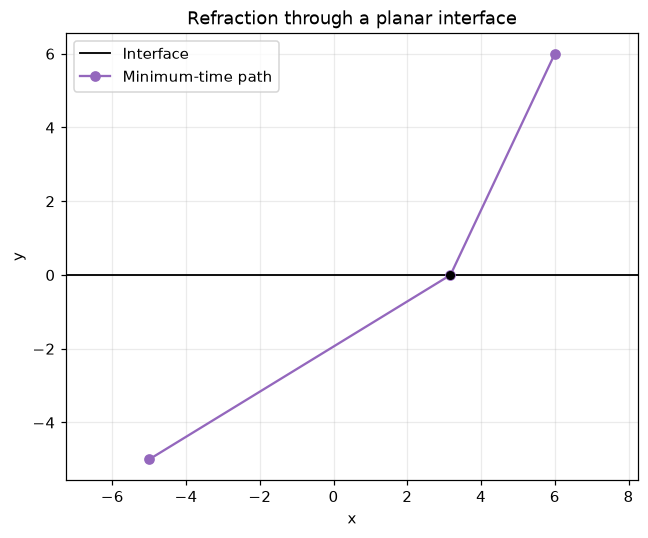

In [9]:
source_point = np.array([6.0, 6.0])
destination_point = np.array([-5.0, -5.0])
source_speed, destination_speed = 1.0, 2.0

def travel_time(interface_x):
    interface_point = np.array([interface_x, 0.0])
    return (
        np.linalg.norm(source_point - interface_point) / source_speed
        + np.linalg.norm(destination_point - interface_point) / destination_speed
    )

refraction_result = minimize_scalar(
    travel_time,
    bounds=(destination_point[0] - 10.0, source_point[0] + 10.0),
    method="bounded",
    options={"xatol": 1e-12},
)
if not refraction_result.success:
    raise RuntimeError(f"Refraction search failed: {refraction_result.message}")
interface_point = np.array([refraction_result.x, 0.0])
source_ray = source_point - interface_point
destination_ray = destination_point - interface_point
incidence_angle = np.arctan2(abs(source_ray[0]), abs(source_ray[1]))
refraction_angle = np.arctan2(abs(destination_ray[0]), abs(destination_ray[1]))
snell_ratio = np.sin(incidence_angle) / np.sin(refraction_angle)
speed_ratio = source_speed / destination_speed
print(
    f"converged={refraction_result.success}; interface point={interface_point}; "
    f"travel time={refraction_result.fun:.8f}; "
    f"incidence={np.degrees(incidence_angle):.6f} deg; "
    f"transmitted={np.degrees(refraction_angle):.6f} deg; "
    f"sin(i)/sin(r)={snell_ratio:.8f}; speed ratio={speed_ratio:.8f}"
)

figure, axes = plt.subplots(figsize=(6, 5))
axes.axhline(0.0, color="black", linewidth=1.2, label="Interface")
axes.plot(
    [source_point[0], interface_point[0], destination_point[0]],
    [source_point[1], interface_point[1], destination_point[1]],
    "o-",
    color="tab:purple",
    label="Minimum-time path",
)
axes.scatter(*interface_point, color="black", s=24, zorder=3)
axes.set(xlabel="x", ylabel="y", title="Refraction through a planar interface")
axes.set_aspect("equal", adjustable="datalim")
axes.grid(True, alpha=0.25)
axes.legend()
figure.tight_layout()
plt.show()


## Conclusions and study prompts

The numerical plots illustrate candidate reflection/refraction paths and the resulting path lengths. Complete the assignment's second-order analysis independently: compute or derive the constrained Hessian at each stationary point, then classify it as a local minimum, maximum, or saddle. In particular, bounded-domain extrema may occur on edges or corners as well as at interior stationary points.

- Derive the tangent-gradient condition for a reflecting surface.
- Derive Snell's law from stationarity of travel time.
- Check how each reported cylinder candidate changes when the angular and height sampling are refined.